In [1]:
!pip install gymnasium matplotlib imageio torch

In [2]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import imageio
from IPython.display import Image, display

# -------------------------------------------------------------
# 1. GÜVENLİK KISITLI ÖZEL SİMÜLASYON ORTAMI (CMDP)
# -------------------------------------------------------------
class SafeNavEnv:
    """Robotun kırmızı tehlikelerden kaçıp yeşil hedefe gittiği 2D ortam"""
    def __init__(self):
        self.goal = np.array([0.8, 0.8])
        # Yolun üstündeki 2 kırmızı tehlike çemberi (merkez ve yarıçap)
        self.hazards = [
            {'pos': np.array([0.0, 0.0]), 'radius': 0.35},
            {'pos': np.array([-0.3, 0.3]), 'radius': 0.25}
        ]
        self.reset()

    def reset(self):
        self.pos = np.array([-0.8, -0.8])
        self.step_count = 0
        return self._get_obs()

    def _get_obs(self):
        to_goal = self.goal - self.pos
        dist_h1 = np.linalg.norm(self.pos - self.hazards[0]['pos'])
        dist_h2 = np.linalg.norm(self.pos - self.hazards[1]['pos'])
        return np.array([self.pos[0], self.pos[1], to_goal[0], to_goal[1], dist_h1, dist_h2], dtype=np.float32)

    def step(self, action):
        self.step_count += 1
        # Eylemler: 0: Dur, 1: Yukarı, 2: Aşağı, 3: Sol, 4: Sağ, 5: Çapraz Sağ-Yukarı
        moves = [
            np.array([0.0, 0.0]),
            np.array([0.0, 0.08]),
            np.array([0.0, -0.08]),
            np.array([-0.08, 0.0]),
            np.array([0.08, 0.0]),
            np.array([0.06, 0.06])
        ]
        self.pos = np.clip(self.pos + moves[action], -1.0, 1.0)

        dist_to_goal = np.linalg.norm(self.pos - self.goal)
        reward = -dist_to_goal  # Hedefe yaklaştıkça ödül artar

        done = False
        if dist_to_goal < 0.12:
            reward += 10.0  # Hedefe ulaşma ödülü
            done = True
        elif self.step_count >= 30:
            done = True

        # Tehlike (Kaza / Maliyet) Kontrolü
        cost = 0.0
        for h in self.hazards:
            if np.linalg.norm(self.pos - h['pos']) < h['radius']:
                cost = 1.0  # Tehlikeli bölgenin içindeyse maliyet yazılır
                break

        return self._get_obs(), reward, cost, done

# -------------------------------------------------------------
# 2. SİNİR AĞLARI
# -------------------------------------------------------------
class PolicyNet(nn.Module):
    def __init__(self, obs_dim=6, act_dim=6):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, act_dim)
        )
    def forward(self, obs):
        return torch.distributions.Categorical(logits=self.net(obs))

class ValueNet(nn.Module):
    def __init__(self, obs_dim=6):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )
    def forward(self, obs):
        return self.net(obs)

# -------------------------------------------------------------
# 3. EĞİTİM FONKSİYONU (Standart vs. PPO-Lagrangian)
# -------------------------------------------------------------
def train_safe_rl(mode="Lagrangian", total_episodes=400):
    print(f"\n🚀 {mode} Modeli Eğitiliyor ({total_episodes} Bölüm)...")
    env = SafeNavEnv()
    policy = PolicyNet()
    v_reward = ValueNet()
    v_cost = ValueNet()

    opt_p = optim.Adam(policy.parameters(), lr=1e-3)
    opt_vr = optim.Adam(v_reward.parameters(), lr=2e-3)
    opt_vc = optim.Adam(v_cost.parameters(), lr=2e-3)

    cost_limit = 2.0       # Bölüm başına tolere edilen maks tehlike adımı
    lagrange_mult = 0.0    # Başlangıç ceza katsayısı
    lambda_lr = 0.05       # Ceza katsayısı güncelleme hızı
    gamma = 0.95

    ep_rewards, ep_costs = [], []

    for ep in range(1, total_episodes + 1):
        obs = env.reset()
        done = False

        states, actions, logprobs, rewards, costs = [], [], [], [], []

        while not done:
            s_t = torch.tensor(obs, dtype=torch.float32)
            dist = policy(s_t)
            a = dist.sample()

            next_obs, r, c, done = env.step(a.item())

            states.append(s_t)
            actions.append(a)
            logprobs.append(dist.log_prob(a))
            rewards.append(r)
            costs.append(c)
            obs = next_obs

        # Getirileri hesapla
        T = len(rewards)
        G_r, G_c = np.zeros(T), np.zeros(T)
        ret_r, ret_c = 0, 0
        for t in reversed(range(T)):
            ret_r = rewards[t] + gamma * ret_r
            ret_c = costs[t] + gamma * ret_c
            G_r[t] = ret_r
            G_c[t] = ret_c

        # Ağ güncellemeleri
        p_loss_total, vr_loss_total, vc_loss_total = 0, 0, 0
        for t in range(T):
            Vr = v_reward(states[t])
            Vc = v_cost(states[t])
            adv_r = torch.tensor(G_r[t], dtype=torch.float32) - Vr.detach()
            adv_c = torch.tensor(G_c[t], dtype=torch.float32) - Vc.detach()

            if mode == "Standard":
                # Standart PPO: Tehlikeyi tamamen görmezden gelir
                actor_loss = -logprobs[t] * adv_r
            else:
                # PPO-Lagrangian: Ödülü artırırken kaza cezasını (lagrange_mult) düşer
                adv_combined = adv_r - lagrange_mult * adv_c
                actor_loss = -logprobs[t] * adv_combined

            p_loss_total += actor_loss
            vr_loss_total += (torch.tensor(G_r[t], dtype=torch.float32) - Vr).pow(2)
            vc_loss_total += (torch.tensor(G_c[t], dtype=torch.float32) - Vc).pow(2)

        opt_p.zero_grad(); p_loss_total.backward(); opt_p.step()
        opt_vr.zero_grad(); vr_loss_total.backward(); opt_vr.step()
        opt_vc.zero_grad(); vc_loss_total.backward(); opt_vc.step()

        # Lagrangian Çarpanı Güncellemesi: Kaza bütçesi aşıldıysa cezayı artır
        total_ep_cost = sum(costs)
        if mode == "Lagrangian":
            lagrange_mult = max(0.0, lagrange_mult + lambda_lr * (total_ep_cost - cost_limit))

        ep_rewards.append(sum(rewards))
        ep_costs.append(total_ep_cost)

        if ep % 50 == 0:
            avg_r = np.mean(ep_rewards[-50:])
            avg_c = np.mean(ep_costs[-50:])
            print(f"[{mode:10s}] Bölüm {ep:3d}/{total_episodes} | Ödül: {avg_r:6.2f} | Kaza Adımı: {avg_c:4.1f} | Lambda: {lagrange_mult:.2f}")

    return ep_rewards, ep_costs, policy

# 1. Standart PPO (Kural Tanımaz)
rew_std, cost_std, policy_std = train_safe_rl("Standard", total_episodes=400)
# 2. Güvenli PPO (PPO-Lagrangian)
rew_safe, cost_safe, policy_safe = train_safe_rl("Lagrangian", total_episodes=400)


🚀 Standard Modeli Eğitiliyor (400 Bölüm)...
[Standard  ] Bölüm  50/400 | Ödül: -57.93 | Kaza Adımı:  3.0 | Lambda: 0.00
[Standard  ] Bölüm 100/400 | Ödül: -44.94 | Kaza Adımı: 11.6 | Lambda: 0.00
[Standard  ] Bölüm 150/400 | Ödül: -40.26 | Kaza Adımı: 12.3 | Lambda: 0.00
[Standard  ] Bölüm 200/400 | Ödül: -36.66 | Kaza Adımı: 10.5 | Lambda: 0.00
[Standard  ] Bölüm 250/400 | Ödül: -26.82 | Kaza Adımı:  9.1 | Lambda: 0.00
[Standard  ] Bölüm 300/400 | Ödül: -20.40 | Kaza Adımı:  8.3 | Lambda: 0.00
[Standard  ] Bölüm 350/400 | Ödül: -19.69 | Kaza Adımı:  8.3 | Lambda: 0.00
[Standard  ] Bölüm 400/400 | Ödül: -19.46 | Kaza Adımı:  8.1 | Lambda: 0.00

🚀 Lagrangian Modeli Eğitiliyor (400 Bölüm)...
[Lagrangian] Bölüm  50/400 | Ödül: -63.23 | Kaza Adımı:  0.5 | Lambda: 0.00
[Lagrangian] Bölüm 100/400 | Ödül: -56.23 | Kaza Adımı:  3.4 | Lambda: 4.45
[Lagrangian] Bölüm 150/400 | Ödül: -54.80 | Kaza Adımı:  1.7 | Lambda: 3.65
[Lagrangian] Bölüm 200/400 | Ödül: -51.85 | Kaza Adımı:  1.8 | Lambda: 3

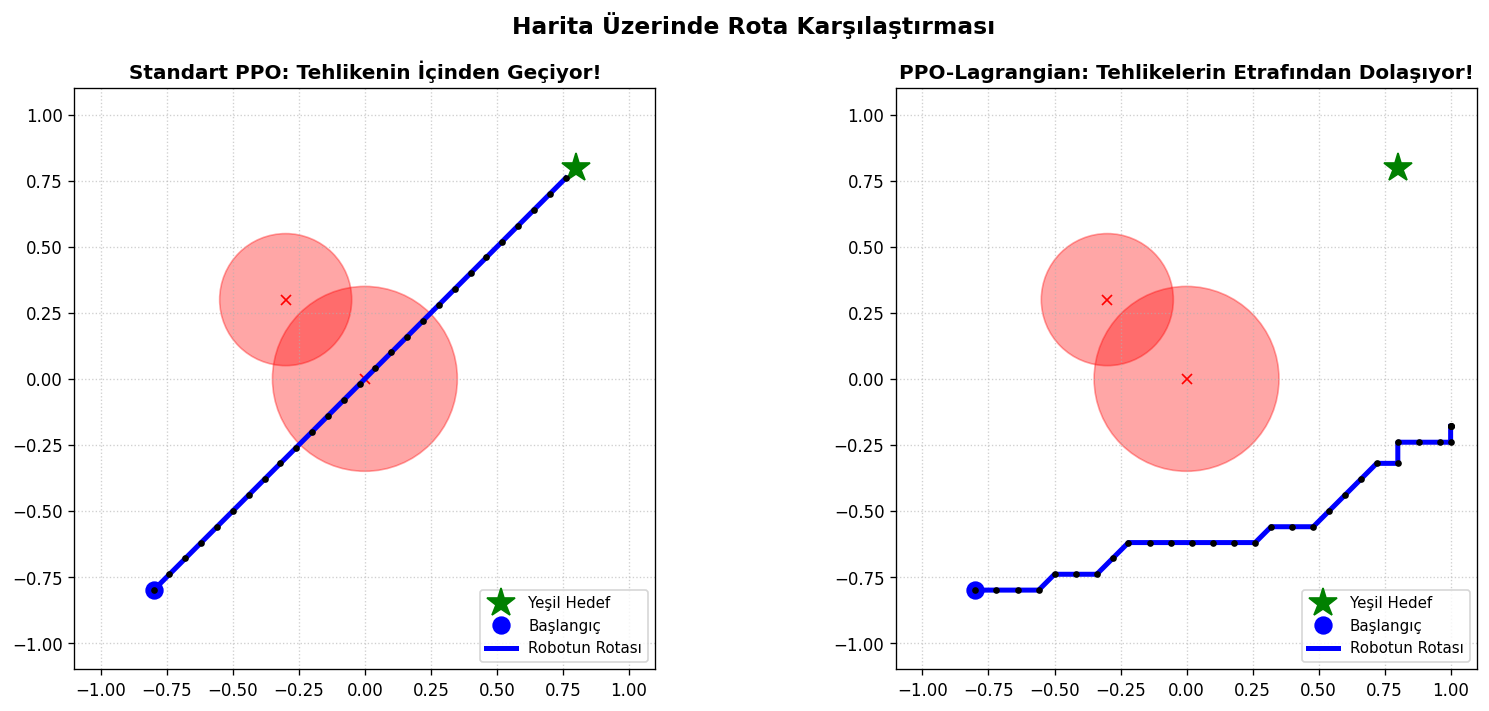


 Rota karşılaştırma görseli 'safe_rl_rotalar.png' olarak kaydedildi!


In [3]:
def plot_trajectory(policy, title, ax):
    env = SafeNavEnv()
    obs = env.reset()
    traj = [env.pos.copy()]
    done = False
    while not done:
        with torch.no_grad():
            dist = policy(torch.tensor(obs, dtype=torch.float32))
            a = dist.sample().item()
        obs, _, _, done = env.step(a)
        traj.append(env.pos.copy())
    traj = np.array(traj)

    # Harita Çizimi
    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    # Tehlikeler (Kırmızı Çemberler)
    for h in env.hazards:
        circle = plt.Circle(h['pos'], h['radius'], color='red', alpha=0.35)
        ax.add_patch(circle)
        ax.plot(h['pos'][0], h['pos'][1], 'rx')
    # Hedef (Yeşil Yıldız)
    ax.plot(env.goal[0], env.goal[1], 'g*', markersize=18, label="Yeşil Hedef")
    # Başlangıç Noktası
    ax.plot(-0.8, -0.8, 'bo', markersize=10, label="Başlangıç")
    # Robotun Çizdiği Rota
    ax.plot(traj[:, 0], traj[:, 1], 'b-', linewidth=3, label="Robotun Rotası")
    ax.plot(traj[:, 0], traj[:, 1], 'k.', markersize=6)

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_aspect('equal')
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc='lower right', fontsize=9)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=120)
plot_trajectory(policy_std, "Standart PPO: Tehlikenin İçinden Geçiyor!", axes[0])
plot_trajectory(policy_safe, "PPO-Lagrangian: Tehlikelerin Etrafından Dolaşıyor!", axes[1])

plt.suptitle("Harita Üzerinde Rota Karşılaştırması", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("safe_rl_rotalar.png")
plt.show()

print("\n Rota karşılaştırma görseli 'safe_rl_rotalar.png' olarak kaydedildi!")